This is a Notebook for a NN to classify MNIST

Load MNIST and display images

(60000, 784)


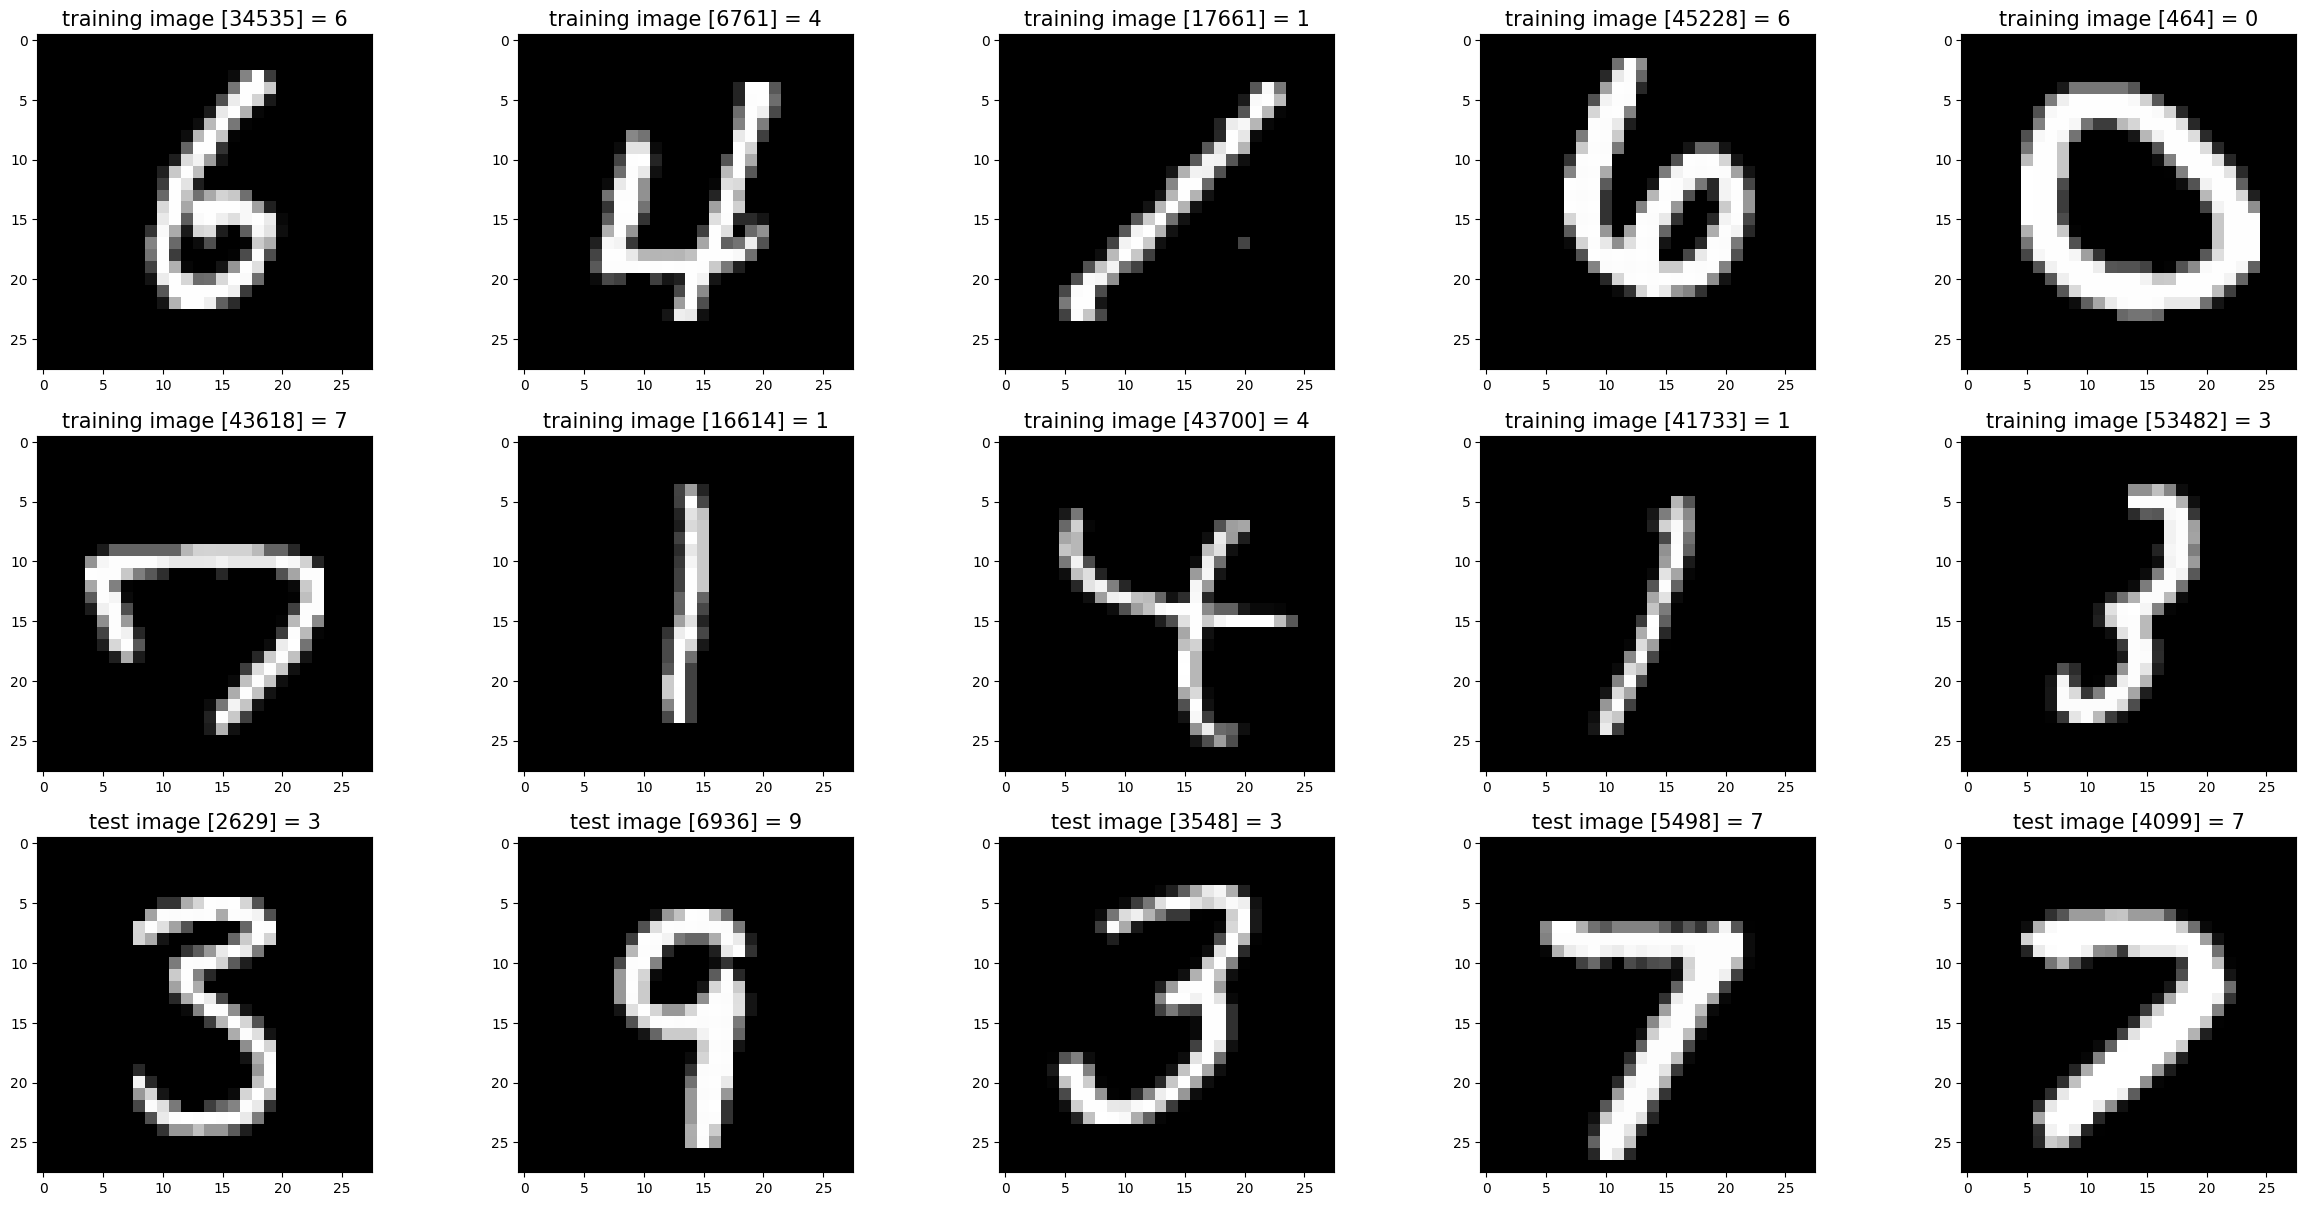

In [ ]:
#
# Verify Reading Dataset via MnistDataloader class
#

import random
import matplotlib.pyplot as plt
from os.path import join
from mnist_data_loader import MnistDataloader
import numpy as np

#
# Set file paths based on added MNIST Datasets
#
input_path = "./MNIST"
training_images_filepath = join(
    input_path, "train-images-idx3-ubyte/train-images-idx3-ubyte"
)
training_labels_filepath = join(
    input_path, "train-labels-idx1-ubyte/train-labels-idx1-ubyte"
)
test_images_filepath = join(input_path, "t10k-images-idx3-ubyte/t10k-images-idx3-ubyte")
test_labels_filepath = join(input_path, "t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte")


#
# Helper function to show a list of images with their relating titles
#
def show_images(images, title_texts):
    cols = 5
    rows = int(len(images) / cols) + 1
    plt.figure(figsize=(30, 20))
    index = 1
    for x in zip(images, title_texts):
        image = x[0]
        title_text = x[1]
        plt.subplot(rows, cols, index)
        plt.imshow(image, cmap=plt.cm.gray)
        if title_text != "":
            plt.title(title_text, fontsize=15)
        index += 1


#
# Load MINST dataset
#
mnist_dataloader = MnistDataloader(
    training_images_filepath,
    training_labels_filepath,
    test_images_filepath,
    test_labels_filepath,
)
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = mnist_dataloader.load_data()

#
# Show some random training and test images
#
images_2_show = []
titles_2_show = []
for i in range(0, 10):
    r = random.randint(1, 60000)
    images_2_show.append(x_train_raw[r])
    titles_2_show.append("training image [" + str(r) + "] = " + str(y_train_raw[r]))

for i in range(0, 5):
    r = random.randint(1, 10000)
    images_2_show.append(x_test_raw[r])
    titles_2_show.append("test image [" + str(r) + "] = " + str(y_test_raw[r]))

show_images(images_2_show, titles_2_show)

#preprocessing
x_train = np.array(x_train_raw, dtype=np.float32)
x_test = np.array(x_test_raw, dtype=np.float32)

x_train = x_train.reshape(len(x_train), -1)
x_test = x_test.reshape(len(x_test), -1)

x_train /= 255.0
x_test /= 255.0


Training

In [12]:
import importlib
import NN_framework
importlib.reload(NN_framework)

w, b = NN_framework.init_NN([30,30,30])

q = NN_framework.forward(w, b, x_train[0])

print(b[-1])
print(q)


[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]


Testing